#1. Scrapping Comments

In [1]:
!pip install youtube-comment-downloader
!pip install pandas

In [2]:
from youtube_comment_downloader import YoutubeCommentDownloader
from youtube_comment_downloader import SORT_BY_POPULAR

import pandas as pd

In [3]:
videos = [

"https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT",

"https://youtu.be/Zr5a1C5UjiA?si=2p14a7KWH0m7BlLd",

"https://youtu.be/KxonHrbF_4k?si=tTcQQYSCIXxGQIKP",

"https://youtu.be/bU-EMmYJSps?si=oSNG-psjW3x9sJWW",

"https://youtu.be/UUTaymXAtqU?si=wmgP5JwxwmohktAS",

"https://youtu.be/9H8yqvCY4vk?si=smLLkmlz7qE90DA8",

]

In [4]:
all_comments = []

downloader = YoutubeCommentDownloader()

for url in videos:

    print("Scraping :", url)

    try:

        comments = downloader.get_comments_from_url(url)

        for c in comments:

            all_comments.append({
                "video": url,
                "comment": c["text"],
                "likes": c["votes"],
                "reply": c["replies"],
                "time": c["time"]
            })

    except:

        print("Error")

Scraping : https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT
Scraping : https://youtu.be/Zr5a1C5UjiA?si=2p14a7KWH0m7BlLd
Scraping : https://youtu.be/KxonHrbF_4k?si=tTcQQYSCIXxGQIKP
Scraping : https://youtu.be/bU-EMmYJSps?si=oSNG-psjW3x9sJWW
Scraping : https://youtu.be/UUTaymXAtqU?si=wmgP5JwxwmohktAS
Scraping : https://youtu.be/9H8yqvCY4vk?si=smLLkmlz7qE90DA8


In [5]:
df = pd.DataFrame(all_comments)

df.to_csv("dataset2.csv", index=False)

print(df.shape)

(580, 5)


#A. Preprocessing and Text Representation

## Load Dataset

In [6]:
df.head()

,video,comment,likes,reply,time
0,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,Opet mata merahh,0,,1 year ago
1,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,Opet mata merahh,0,,1 year ago
2,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,Opet mata merahh,1,,1 year ago
3,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,"malas itu karena bocah nya, AI itu tekhnologi ...",0,,1 year ago
4,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,bukankah teknologi itu tercipta karena manusia...,1,,2 years ago


In [7]:
from google.colab import files

files.download("dataset2.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Import Library

In [8]:
!pip install Sastrawi

In [9]:
import pandas as pd
import numpy as np
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [10]:
import pandas as pd

df = pd.read_csv("dataset2.csv")

df.head()

,video,comment,likes,reply,time
0,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,Opet mata merahh,0,NaN,1 year ago
1,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,Opet mata merahh,0,NaN,1 year ago
2,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,Opet mata merahh,1,NaN,1 year ago
3,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,"malas itu karena bocah nya, AI itu tekhnologi ...",0,NaN,1 year ago
4,https://youtu.be/djOlA8MOFSo?si=bN_VW4_plkag1ieT,bukankah teknologi itu tercipta karena manusia...,1,NaN,2 years ago


In [11]:
print(df.shape)

(580, 5)


##Preprocessing

### ambil kolom comment

In [12]:
df = df[['comment']]

df.head()

,comment
0,Opet mata merahh
1,Opet mata merahh
2,Opet mata merahh
3,"malas itu karena bocah nya, AI itu tekhnologi ..."
4,bukankah teknologi itu tercipta karena manusia...


### drop na dan duplicate

In [13]:
df.dropna(inplace=True)

df.drop_duplicates(inplace=True)

df.reset_index(drop=True, inplace=True)

print(df.shape)

(559, 1)


In [14]:
df["word_count"] = df["comment"].str.split().str.len()

df = df[df["word_count"] >= 4]

###stopword dan stemmer

In [15]:
stop_words = set(stopwords.words('indonesian'))

custom_stopwords = {

"yg","aja","nya","ga","gak","nggak","udah","udahh",
"bang","bro","bre","kak","nih","dong","kok","lah",
"mah","deh","sih","ya","yah","kan","pun",
"gw","gue","gua","lu","loe","lo",
"pak","bu","u","i","n","w","p","l","a","b",
"amp","https","http"

}

stop_words = stop_words.union(custom_stopwords)
factory = StemmerFactory()
stemmer = factory.create_stemmer()

### cleaning function

In [16]:
def preprocessing(text):

    # lowercase
    text = text.lower()

    # hapus url
    text = re.sub(r"http\S+", "", text)

    # hapus mention
    text = re.sub(r"@\w+", "", text)

    # hapus hashtag
    text = re.sub(r"#\w+", "", text)

    # hapus angka
    text = re.sub(r"\d+", "", text)

    # hapus punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # hapus spasi berlebih
    text = text.strip()

    # tokenisasi
    tokens = word_tokenize(text)

    # stopword
    tokens = [w for w in tokens if w not in stop_words]

    tokens = [w for w in tokens if w not in custom_stopwords]

    # buang token 1 huruf
    tokens = [w for w in tokens if len(w) > 1]


    # stemming
    tokens = [stemmer.stem(w) for w in tokens]

    return " ".join(tokens)

In [17]:
df["clean_comment"] = df["comment"].astype(str).apply(preprocessing)

df.head()

,comment,word_count,clean_comment
1,"malas itu karena bocah nya, AI itu tekhnologi ...",26,malas bocah ai tekhnologi gantung maka kalo ma...
2,bukankah teknologi itu tercipta karena manusia...,8,teknologi cipta manusia malas
4,Haruskah PEMERINTAH yang MALAS nggak GUNA di G...,15,harus perintah malas ganti i rapat cuman tidur...
5,Justru lebih enak mendengar penjelasan dari ai...,30,enak dengar jelas ai ketimbang guru dosen ai t...
6,AI dulu pas saya sekolah..pas Ujian..adalah Ka...,7,ai pas sekolahpas ujianadalah kalkulator


In [18]:
df.to_csv("clean_dataset.csv", index=False)

##Text Representation

### Text representation 1 : TF-IDF

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=3000)

X_tfidf = tfidf.fit_transform(df["clean_comment"])

print(X_tfidf.shape)

(501, 1990)


### Text Representation 2 : SentenceTransformer (Sentence-BERT)

In [20]:
pip install sentence-transformers

In [21]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('all-MiniLM-L6-v2')

X_bert = model.encode(
    df["clean_comment"].tolist(),
    show_progress_bar=True
)

print(X_bert.shape)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

(501, 384)


#B. Pengelompokan komentar dengan menggunakan pendekatan clustering dan perbandingan silhoutte score sebagai justifikasi jumlah cluster (k) yang dipilih.

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

## clustering TF-IDF

In [23]:
tfidf_scores = []

for k in range(2, 10):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_tfidf)

    score = silhouette_score(X_tfidf, labels)

    tfidf_scores.append(score)

    print(f"K = {k} | Silhouette Score = {score:.4f}")

K = 2 | Silhouette Score = 0.0069
K = 3 | Silhouette Score = 0.0071
K = 4 | Silhouette Score = 0.0067
K = 5 | Silhouette Score = 0.0042
K = 6 | Silhouette Score = 0.0062
K = 7 | Silhouette Score = 0.0088
K = 8 | Silhouette Score = 0.0104
K = 9 | Silhouette Score = 0.0088


##clustering Sentence-BERT

In [24]:
bert_scores = []

for k in range(2, 10):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_bert)

    score = silhouette_score(X_bert, labels)

    bert_scores.append(score)

    print(f"K = {k} | Silhouette Score = {score:.4f}")

K = 2 | Silhouette Score = 0.0748
K = 3 | Silhouette Score = 0.0296
K = 4 | Silhouette Score = 0.0293
K = 5 | Silhouette Score = 0.0093
K = 6 | Silhouette Score = 0.0031
K = 7 | Silhouette Score = 0.0107
K = 8 | Silhouette Score = 0.0117
K = 9 | Silhouette Score = 0.0072


## perbandingan

In [25]:
comparison = pd.DataFrame({
    "K": range(2,10),
    "TF-IDF": tfidf_scores,
    "Sentence-BERT": bert_scores
})

comparison

,K,TF-IDF,Sentence-BERT
0,2,0.006878,0.074772
1,3,0.007146,0.029587
2,4,0.006698,0.029332
3,5,0.004159,0.009336
4,6,0.006201,0.003126
5,7,0.008798,0.010681
6,8,0.010367,0.011736
7,9,0.008789,0.007200


Silhouette Score Sentence-BERT selalu lebih tinggi dibanding TF-IDF.Artinya representasi Sentence-BERT lebih mampu menangkap makna komentar sehingga cluster yang terbentuk lebih baik.

Karena silhouette terbesar ada pada K=2, yaitu 0.074, maka jumlah cluster yang dipilih adalah 2.

##visualisasi

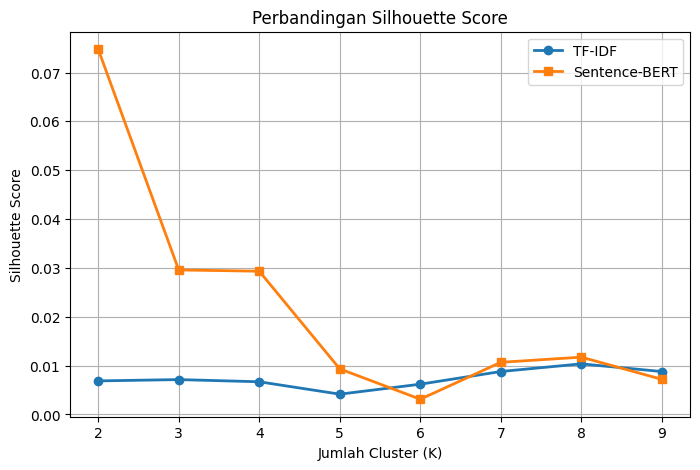

In [26]:
plt.figure(figsize=(8,5))

plt.plot(comparison["K"], comparison["TF-IDF"], marker="o", linewidth=2, label="TF-IDF")

plt.plot(comparison["K"], comparison["Sentence-BERT"], marker="s", linewidth=2, label="Sentence-BERT")

plt.title("Perbandingan Silhouette Score")

plt.xlabel("Jumlah Cluster (K)")

plt.ylabel("Silhouette Score")

plt.legend()

plt.grid(True)

plt.show()

## clustering

In [27]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X_bert)

In [28]:
df["cluster"].value_counts()

,count
cluster,
0,329
1,172


#C. Persona Analysis dari cluster yang dihasilkan

In [29]:
for i in sorted(df.cluster.unique()):

    print("="*80)
    print(i)

    print(df[df.cluster==i]["comment"].head(20))

0
1     malas itu karena bocah nya, AI itu tekhnologi ...
4     Haruskah PEMERINTAH yang MALAS nggak GUNA di G...
5     Justru lebih enak mendengar penjelasan dari ai...
6     AI dulu pas saya sekolah..pas Ujian..adalah Ka...
7     Keren yah skrg ai jauh lebih pintar😂 wah kita ...
10    Faktanya penjelasan dari chat gpt lebih bisa d...
12                           Masa iya bikin siswa malas
14    Jadi pisau bermata dua klo pemerintahnya sendi...
15    g ada emosi ndro, emang bisa bercanda ama ai :...
16    Memang benar memudahkan, tpi AI tdk bisa mengg...
17     @RidhAnzari  AI memang diciptakan bukan untuk...
19    ​ @akunakun3145 Ofc ada kak, dgn cara mengajar...
20    di dunia pendidikan guru dan siswa menggunakan...
21    Cisssss\nBikin poster kok pakai Gemini, \n\nNg...
22    gak apa2 sih. toh guru nya juga gak ada inovas...
24    Ai itu penting untuk kehidupan sehari-hari yg ...
25    Kalau tujuannya untuk hasil instant bisa bikin...
26    AI cocok dipakai sebagai asisten belajar

Cluster 0 : Kelompok ini berisi komentar yang memiliki persepsi positif terhadap penggunaan AI dalam pendidikan. Mayoritas pengguna menilai AI dapat membantu proses belajar, mempermudah pemahaman materi, serta berperan sebagai asisten belajar. Walaupun demikian, sebagian komentar tetap menegaskan bahwa AI tidak dapat menggantikan peran guru sepenuhnya.

"Justru lebih enak mendengar penjelasan dari AI ketimbang guru atau dosen."

"Faktanya penjelasan dari ChatGPT lebih bisa dipahami dibanding dosen."

"AI cocok dipakai sebagai asisten belajar, bukan pesuruh pencari jawaban."

"AI itu penting untuk kehidupan sehari-hari, yang salah itu penggunanya."

"AI memang diciptakan bukan untuk menggantikan manusia, tetapi untuk membantu efektivitas pembelajaran."

"Memang benar memudahkan, tapi AI tidak bisa menggantikan manusia karena manusia punya perasaan."


Cluster 1 : Kelompok ini terdiri dari pengguna yang menunjukkan sikap lebih berhati-hati terhadap penggunaan AI dalam pendidikan. Sebagian besar komentar mengungkapkan kekhawatiran bahwa AI dapat menyebabkan ketergantungan, menurunkan kemampuan berpikir kritis, atau membuat siswa menjadi malas. Selain itu, terdapat pula komentar yang bersifat netral, seperti apresiasi terhadap video maupun komentar umum yang tidak secara langsung menunjukkan dukungan atau penolakan terhadap AI.

"Bukankah teknologi itu tercipta karena manusia itu malas?"

"Masa iya bikin siswa malas."

"Ancaman dong, sebentar lagi sekolah tutup."

"Kalau tujuannya untuk hasil instan bisa bikin penurunan IQ."

"Saya belum bisa penggunaan AI."

"Sebagai pembanding saja, tidak menjadi rujukan satu-satunya."



#D. Topic Extraction

Latent Dirichlet Allocation (LDA) merupakan salah satu metode unsupervised learning yang digunakan untuk melakukan topic extraction atau menemukan topik-topik tersembunyi dari sekumpulan dokumen. Pada metode ini, setiap dokumen dianggap sebagai kombinasi dari beberapa topik, sedangkan setiap topik direpresentasikan oleh kumpulan kata yang memiliki probabilitas kemunculan tinggi. Dalam penelitian ini, LDA digunakan untuk mengidentifikasi tema utama yang sering dibahas oleh pengguna YouTube mengenai dampak kecerdasan buatan (AI) dalam pendidikan.

## import library

In [30]:
!pip install gensim

In [31]:
import gensim
from gensim import corpora
from gensim.models import LdaModel

##tokenisasi

In [32]:
texts = [text.split() for text in df["clean_comment"]]

##dictionary

In [33]:
dictionary = corpora.Dictionary(texts)

##corpus

In [34]:
corpus = [dictionary.doc2bow(text) for text in texts]

##cek banyak jumlah topik yang digunakan

In [35]:
for num_topics in [2,3,4]:

    print("="*80)
    print(f"LDA dengan {num_topics} Topik")
    print("="*80)

    lda = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=num_topics,
        random_state=42,
        passes=20
    )

    for idx, topic in lda.print_topics():
        print(f"Topik {idx+1}")
        print(topic)
        print()

LDA dengan 2 Topik
Topik 1
0.061*"ai" + 0.013*"ajar" + 0.011*"guru" + 0.010*"bikin" + 0.010*"pake" + 0.007*"didik" + 0.006*"anak" + 0.006*"pakai" + 0.005*"salah" + 0.005*"bantu"

Topik 2
0.023*"ai" + 0.013*"ajar" + 0.008*"sekolah" + 0.008*"teknologi" + 0.007*"paham" + 0.007*"didik" + 0.006*"pikir" + 0.006*"pakai" + 0.006*"gantung" + 0.006*"orang"

LDA dengan 3 Topik
Topik 1
0.061*"ai" + 0.010*"ajar" + 0.010*"pake" + 0.010*"bikin" + 0.009*"guru" + 0.008*"pakai" + 0.007*"anak" + 0.006*"kalo" + 0.006*"manusia" + 0.006*"salah"

Topik 2
0.033*"ai" + 0.014*"ajar" + 0.010*"sekolah" + 0.010*"gantung" + 0.009*"paham" + 0.008*"pakai" + 0.007*"teknologi" + 0.006*"pikir" + 0.006*"hafal" + 0.005*"kerja"

Topik 3
0.038*"ai" + 0.014*"ajar" + 0.012*"didik" + 0.008*"bikin" + 0.008*"guru" + 0.007*"indonesia" + 0.007*"banget" + 0.006*"orang" + 0.006*"pake" + 0.005*"salah"

LDA dengan 4 Topik
Topik 1
0.062*"ai" + 0.013*"bikin" + 0.012*"ajar" + 0.011*"guru" + 0.010*"pake" + 0.009*"pakai" + 0.009*"anak" + 0

#E. Persona Analysis Topic Extraction

In [37]:
for i in range(2):
    print(f"Topik {i+1}")
    print(lda.show_topic(i, topn=20))

Topik 1
[('ai', np.float32(0.062441003)), ('bikin', np.float32(0.012657361)), ('ajar', np.float32(0.012325407)), ('guru', np.float32(0.010862912)), ('pake', np.float32(0.01046081)), ('pakai', np.float32(0.009124112)), ('anak', np.float32(0.009023846)), ('didik', np.float32(0.0054751583)), ('manusia', np.float32(0.0054411567)), ('bagus', np.float32(0.0052936915)), ('kerja', np.float32(0.005254058)), ('kalo', np.float32(0.0051873215)), ('banget', np.float32(0.005186738)), ('salah', np.float32(0.005103117)), ('bantu', np.float32(0.0044071404)), ('kurikulum', np.float32(0.004268557)), ('tugas', np.float32(0.0042034523)), ('indonesia', np.float32(0.004130271)), ('biar', np.float32(0.004013673)), ('beda', np.float32(0.0039937715))]
Topik 2
[('ai', np.float32(0.026944729)), ('ajar', np.float32(0.013895826)), ('paham', np.float32(0.011901959)), ('gantung', np.float32(0.011437319)), ('teknologi', np.float32(0.0106954435)), ('sekolah', np.float32(0.009460144)), ('hafal', np.float32(0.007284822))

Topik 1 : Topik ini menggambarkan pembahasan mengenai penggunaan AI sebagai alat bantu dalam proses belajar mengajar. Kata-kata seperti AI, guru, ajar, bantu, dan anak menunjukkan bahwa sebagian besar komentar membahas bagaimana AI dimanfaatkan untuk mendukung kegiatan pembelajaran tanpa sepenuhnya menggantikan peran guru.

Topik 2 : Topik ini lebih banyak membahas dampak penggunaan AI terhadap proses pembelajaran. Kata-kata seperti teknologi, pikir, gantung, dan sekolah menunjukkan adanya diskusi mengenai potensi ketergantungan terhadap AI serta pengaruhnya terhadap kemampuan berpikir siswa.

###Perbandingan :

Hasil clustering menunjukkan bahwa komentar masyarakat terbagi menjadi dua kelompok utama, yaitu kelompok yang mendukung penggunaan AI dalam pendidikan dan kelompok yang lebih skeptis atau netral terhadap penggunaan AI. Sementara itu, hasil topic extraction tidak berfokus pada kelompok pengguna, melainkan pada tema pembahasan yang muncul, yaitu pemanfaatan AI sebagai pendukung pembelajaran dan dampak AI terhadap proses belajar. Dengan demikian, clustering memberikan gambaran mengenai karakteristik pengguna, sedangkan topic extraction memberikan gambaran mengenai isu atau tema yang paling banyak dibahas. Kedua metode memberikan sudut pandang yang berbeda namun saling melengkapi dalam memahami opini masyarakat mengenai penggunaan AI di bidang pendidikan.